In [1]:
import mitsuba as mi
import drjit as dr

import numpy as np

import matplotlib.pyplot as plt

import random

import importlib
import sys
from pathlib import Path

from PIL import Image
import cv2

import os

if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")

import utils

print(sys.path)

jitc_llvm_init(): LLVM API initialization failed ..


['p:\\Programs\\miniconda3\\envs\\master-pytorch\\python313.zip', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\DLLs', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch', '', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32\\lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\Pythonwin', 'd:\\Studium\\Masters\\Masters\\scripts\\..\\src']


# Gameplan regarding mitsuba implementation 

- Play around just with pathtracer to get more of a feeling
- Play around with dr. jit a bit
    - Need to install a newer version I think
    - Maybe try to implement something with InstantNGP (learning an image ?)
- Try to reimplement reparameterization network on images! in dr. jit
- Figure out how I would get access to training data from a renderer
- Figure out how to train
- Build some debugging tools!!
    - At least I need to be able to evaluate model at specific points in the world
    - Maybe even be able to create a reference luminance distribution at those points
    - Something to compare Images with network vs those without
    - RMSE compares
- Extend to online/offline training etc.

In [4]:
print(mi.variants())

# mi.set_variant("llvm_ad_rgb")
mi.set_variant("cuda_ad_rgb")

['scalar_rgb', 'scalar_spectral', 'scalar_spectral_polarized', 'llvm_ad_rgb', 'llvm_ad_mono', 'llvm_ad_mono_polarized', 'llvm_ad_spectral', 'llvm_ad_spectral_polarized', 'cuda_ad_rgb', 'cuda_ad_mono', 'cuda_ad_mono_polarized', 'cuda_ad_spectral', 'cuda_ad_spectral_polarized']


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3039.6401].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3039.6406].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3039.6401].


Text(0.5, 1.0, 'mis sampling')

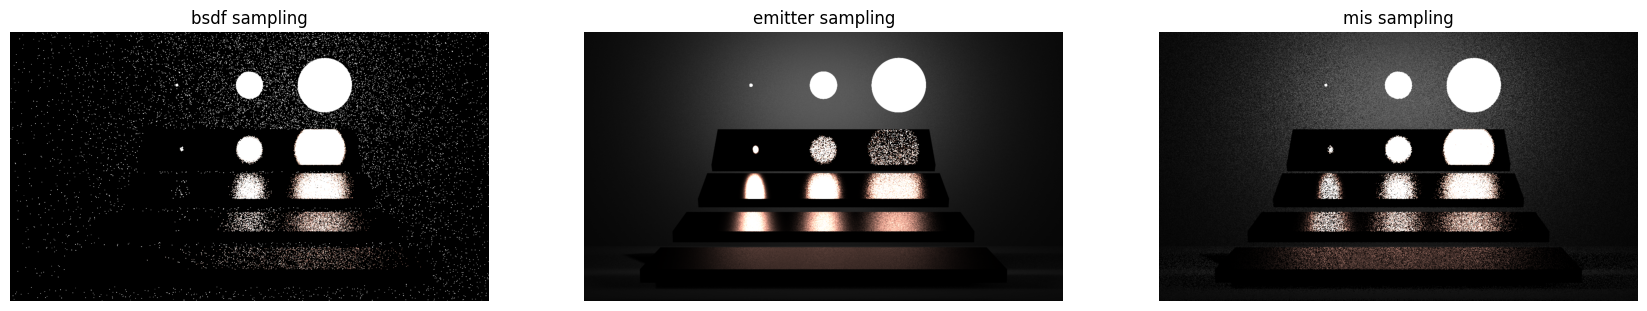

In [5]:
veach_mis = mi.load_file("../assets/scenes/veach_mis/scene_v3.xml")

spp = 64

integrator_bsdf = mi.load_dict({
    'type': 'direct',
    'emitter_samples': 0,
    'bsdf_samples': 1
})

integrator_emitter_sampling = mi.load_dict({
    'type': 'direct',
    'emitter_samples': 1,
    'bsdf_samples': 0
})

integrator_mis = mi.load_dict({
    'type': 'direct',
    'emitter_samples': 1,
    'bsdf_samples': 1
})


img_bsdf = mi.render(veach_mis, integrator=integrator_bsdf, spp=1)
img_emSampling = mi.render(veach_mis, integrator=integrator_emitter_sampling, spp=spp)
img_mis = mi.render(veach_mis, integrator=integrator_mis, spp=1)

img_emSampling

fig, axs = plt.subplots(1, 3, figsize=(21, 7))
axs[0].axis('off')
axs[0].imshow(img_bsdf)
axs[0].set_title("bsdf sampling")

axs[1].axis('off')
axs[1].imshow(img_emSampling)
axs[1].set_title("emitter sampling")

axs[2].axis('off')
axs[2].imshow(img_mis)
axs[2].set_title("mis sampling")

In [6]:
params: mi.SceneParameters = mi.traverse(veach_mis)

cam = mi.ProjectiveCamera = veach_mis.sensors()[0]

print(cam.world_transform())

Transform[
  matrix=[[[-4.37113e-08, 0, -1, 28.2792],
           [0, 1, 0, 3.5],
           [1, 0, -4.37113e-08, 1.23612e-06],
           [0, 0, 0, 1]]],
  inverse_transpose=[[[-4.37113e-08, 0, -1, 0],
                      [0, 1, 0, 0],
                      [1, 0, -4.37113e-08, 0],
                      [5.9496e-13, -3.5, 28.2792, 1]]]
]


# Unfinished test scripting own full renderer below

TODO: I think I ultimately need to do it like to get access to the values I need for training and to sample new directions from my network

In [7]:
# cbox: mi.Scene = mi.load_dict(mi.cornell_box())

##### Gathering functions which will be a part of my final renderer implementation
#### Note: functions may not be 100% syntactically correct or require additional arguments etc.


### Emitter Sampling
# emitter_id = cbox.sample_emitter # Sample an Emitter
# cbox.emitters_dr()[emitter_id].sample_position() # Sample 

## I might not need that much more ?
## I already know how to implement a renderer

### Pseudo code:

"""
1. Sample initial rays
2. Compute Surface Interaction
3. Compute outgoing directions
4. compute bsdf values with outgoing directions
5. If material is emissive -> compute emission
6. Render loop
"""

'\n1. Sample initial rays\n2. Compute Surface Interaction\n3. Compute outgoing directions\n4. compute bsdf values with outgoing directions\n5. If material is emissive -> compute emission\n6. Render loop\n'

In [8]:
from mitsuba import ScalarTransform4f as T

cbox: mi.Scene = mi.load_dict({
        'type': 'scene',
        'integrator': {
            'type': 'path',
            'max_depth': 8
        },
        # -------------------- Sensor --------------------
        'sensor': {
            'type': 'perspective',
            'fov_axis': 'smaller',
            'near_clip': 0.001,
            'far_clip': 100.0,
            'focus_distance': 1000,
            'fov': 39.3077,
            'to_world': T().look_at(
                origin=[0, 0, 3.90],
                target=[0, 0, 0],
                up=[0, 1, 0]
            ),
            'sampler': {
                'type': 'independent',
                'sample_count': 64
            },
            'film': {
                'type': 'hdrfilm',
                'width' : 256,
                'height': 256,
                'rfilter': {
                    'type': 'gaussian',
                },
                'pixel_format': 'rgb',
                'component_format': 'float32',
            }
        },
        # -------------------- BSDFs --------------------
        'white': {
            'type': 'diffuse',
            'reflectance': {
                'type': 'rgb',
                'value': [0.885809, 0.698859, 0.666422],
            }
        },
        'green': {
            'type': 'diffuse',
            'reflectance': {
                'type': 'rgb',
                'value': [0.105421, 0.37798, 0.076425],
            }
        },
        'red': {
            'type': 'diffuse',
            'reflectance': {
                'type': 'rgb',
                'value': [0.570068, 0.0430135, 0.0443706],
            }
        },
        'blue': {
            'type': 'diffuse',
            'reflectance': {
                'type': 'rgb',
                'value': [0.188, 0.235, 0.820],
            }
        },
        # -------------------- Light --------------------
        'light': {
            'type': 'rectangle',
            'to_world': T().translate([0.0, 0.99, 0.01]).rotate([1, 0, 0], 90).scale([0.23, 0.19, 0.19]),
            'bsdf': {
                'type': 'ref',
                'id': 'white'
            },
            'emitter': {
                'type': 'area',
                'radiance': {
                    'type': 'rgb',
                    'value': [18.387, 13.9873, 6.75357],
                }
            }
        },
        # -------------------- Shapes --------------------
        'floor': {
            'type': 'rectangle',
            'to_world': T().translate([0.0, -1.0, 0.0]).rotate([1, 0, 0], -90),
            'bsdf': {
                'type': 'ref',
                'id':  'white'
            }
        },
        'ceiling': {
            'type': 'rectangle',
            'to_world': T().translate([0.0, 1.0, 0.0]).rotate([1, 0, 0], 90),
            'bsdf': {
                'type': 'ref',
                'id':  'white'
            }
        },
        'back': {
            'type': 'rectangle',
            'to_world': T().translate([0.0, 0.0, -1.0]),
            'bsdf': {
                'type': 'ref',
                'id':  'white'
            }
        },
        'green-wall': {
            'type': 'rectangle',
            'to_world': T().translate([1.0, 0.0, 0.0]).rotate([0, 1, 0], -90),
            'bsdf': {
                'type': 'ref',
                'id':  'green'
            }
        },
        'red-wall': {
            'type': 'rectangle',
            'to_world': T().translate([-1.0, 0.0, 0.0]).rotate([0, 1, 0], 90),
            'bsdf': {
                'type': 'ref',
                'id':  'red'
            }
        },
        'small-box': {
            'type': 'cube',
            'to_world': T().translate([0.335, -0.7, 0.38]).rotate([0, 1, 0], -17).scale(0.3),
            'bsdf': {
                'type': 'ref',
                'id':  'blue'
            }
        },
        'large-box': {
            'type': 'cube',
            'to_world': T().translate([-0.33, -0.4, -0.28]).rotate([0, 1, 0], 18.25).scale([0.3, 0.61, 0.3]),
            'bsdf': {
                'type': 'ref',
                'id':  'red'
            }
        },
    })

In [9]:
test_env_scene: mi.Scene = mi.load_dict({
        'type': 'scene',
        'integrator': {
            'type': 'path',
            'max_depth': 8
        },
        # -------------------- Sensor --------------------
        'sensor': {
            'type': 'perspective',
            'fov_axis': 'smaller',
            'near_clip': 0.001,
            'far_clip': 100.0,
            'focus_distance': 1000,
            'fov': 39.3077,
            'to_world': T().look_at(
                origin=[0, 0, 6],
                target=[0, 0, 0],
                up=[0, 1, 0]
            ),
            'sampler': {
                'type': 'independent',
                'sample_count': 64
            },
            'film': {
                'type': 'hdrfilm',
                'width' : 256,
                'height': 256,
                'rfilter': {
                    'type': 'gaussian',
                },
                'pixel_format': 'rgb',
                'component_format': 'float32',
            }
        },
        # -------------------- BSDFs --------------------
        'white': {
            'type': 'diffuse',
            'reflectance': {
                'type': 'rgb',
                'value': [0.885809, 0.698859, 0.666422],
            }
        },
        # -------------------- Env Map --------------------
        'emitter_id': {
            'type': 'envmap',
            'filename': '../assets/test_distributions/museum.jpg'
        },
        # -------------------- Shapes --------------------
        'object': {
            'type': 'sphere',
            'to_world': T(),
            'bsdf': {
                'type': 'ref',
                'id':  'white'
            }
        },
    })

In [10]:
sens: mi.Sensor = mi.load_dict({
    'type': 'perspective',
    'fov': 39.3077,
    'to_world': T().look_at(
        origin=[0, 0, 4],
        target=[0, 0, 0],
        up=[0, 1, 1]
    ),
    'sampler': {
        'type': 'independent',
        'sample_count': 16
    },
    'film': {
        'type': 'hdrfilm',
        'width': 256,
        'height': 256,
        'rfilter': {
            'type': 'tent',
        },
        'pixel_format': 'rgb',
    }
})


In [11]:
cbox_params = mi.traverse(cbox)

cbox_params["light.emitter.radiance.value"] *= 3
cbox_params.update()

# for p in cbox_params:
#     print(p[0])

[(SRGBReflectanceSpectrum[
    value = [[55.161, 41.9619, 20.2607]]
  ],
  {'value'}),
 (AreaLight[
    radiance = SRGBReflectanceSpectrum[
      value = [[55.161, 41.9619, 20.2607]]
    ],
    surface_area = [0.1748],
    <no medium attached!>
  ],
  {'radiance'}),
 (Rectangle[
    to_world = [[0.23, 0, 0, 0],
                [0, -8.30516e-09, -0.19, 0.99],
                [0, 0.19, -8.30516e-09, 0.01],
                [0, 0, 0, 1]],
    frame = Frame[
      s=[[0.46, 0, 0]],
      t=[[0, -1.66103e-08, 0.38]],
      n=[[0, -1, -4.37114e-08]]
    ],
    surface_area = [0.1748],
    bsdf = SmoothDiffuse[
      reflectance = SRGBReflectanceSpectrum[
        value = [[0.885809, 0.698859, 0.666422]]
      ]
    ],
    emitter = AreaLight[
      radiance = SRGBReflectanceSpectrum[
        value = [[55.161, 41.9619, 20.2607]]
      ],
      surface_area = [0.1748],
      <no medium attached!>
    ]
  ],
  {'emitter'}),
 (Scene[
    children = [
      PathIntegrator[
        max_depth = 8,
  

In [14]:
import scenes

importlib.reload(scenes)

import scenes


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.063300684..12.376532].


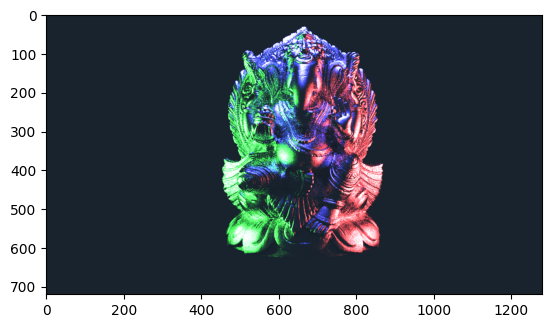

In [68]:
scene_name = "ganesha"
# scene_name = "kitchen"
# scene_name = "glossy_cbox"
# scene_name = "cbox_inverted_light"

scene = scenes.get_scene_by_name(scene_name)

img = mi.render(scene, spp = 32)

plt.imshow(img)

rendering batch 1 of 16
rendering batch 2 of 16
rendering batch 3 of 16
rendering batch 4 of 16
rendering batch 5 of 16
rendering batch 6 of 16
rendering batch 7 of 16
rendering batch 8 of 16
rendering batch 9 of 16
rendering batch 10 of 16
rendering batch 11 of 16
rendering batch 12 of 16
rendering batch 13 of 16
rendering batch 14 of 16
rendering batch 15 of 16
rendering batch 16 of 16
1280 720


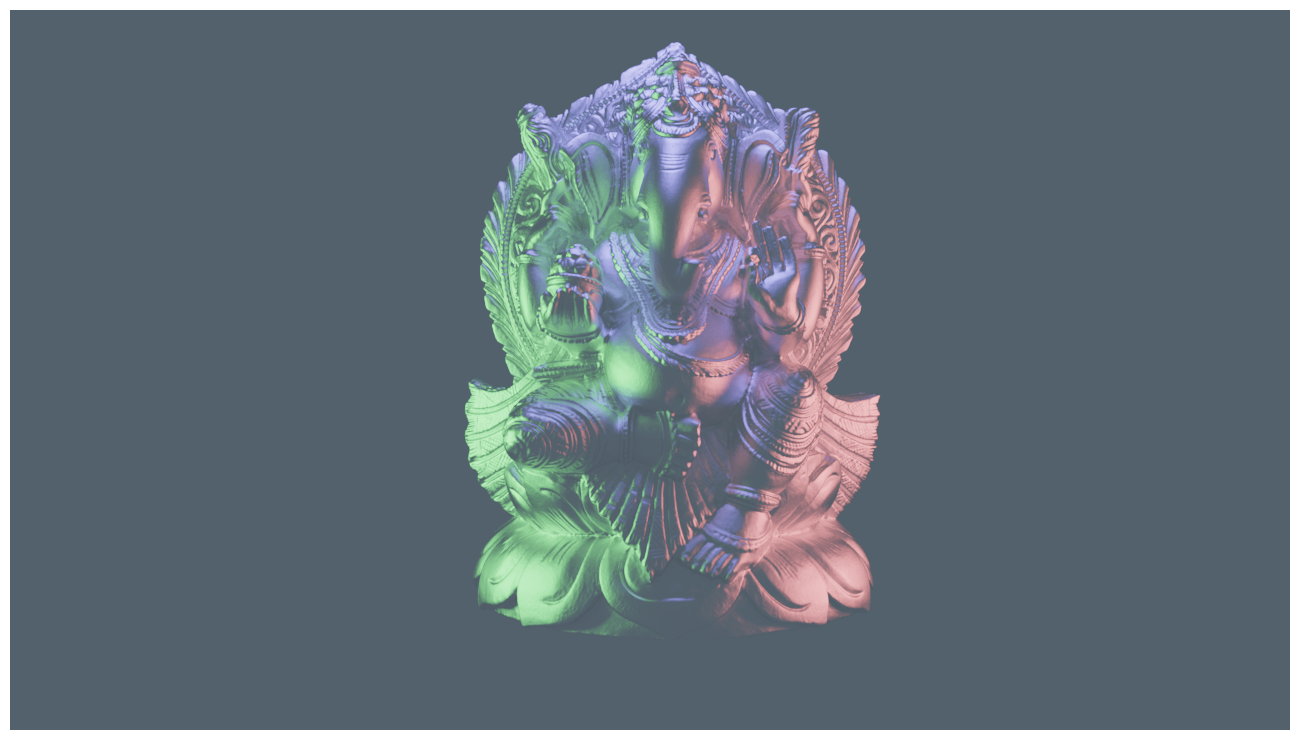

In [69]:
# scene_name = "env_scene_sphere_metallic"
# scene_name = "env_scene_sphere_dielectric"
# scene_name = "spaceship"
# scene_name = "veach_ajar"
# scene_name = "living_room_2"
# scene_name = "cbox"

scene_name = "ganesha"
# scene_name = "kitchen"
# scene_name = "glossy_cbox"
# scene_name = "cbox_inverted_light"

scene = scenes.get_scene_by_name(scene_name)

params = mi.traverse(scene)

use_custom_size = False
if use_custom_size:
    w = 512
    h = 512
    params["sensor.film.size"] = mi.ScalarVector2u(w, h)
    params.update()

batch_size = 2**8
num_batches = 2**4

out_buffer = None
out_img_dr = None
for i in range(num_batches):
    print(f"rendering batch {i + 1} of {num_batches}")
    img = mi.render(scene, spp=batch_size,  seed=mi.UInt32(random.randint(0, 1000000)))
    if out_img_dr is None:
        out_img_dr = img
    else:
        out_img_dr += img

    if out_buffer is None:
        out_buffer = np.array(img, dtype=np.float32)
    else:
        out_buffer += np.array(img, dtype=np.float32)


out_buffer /= num_batches
out_img_dr /= num_batches

ref_dir = "../../thesis_assets/images/references"
file_path_no_ext = f"{ref_dir}/reference_{scene_name}"

mi.util.write_bitmap(f"{file_path_no_ext}.exr", out_img_dr)

mi.util.write_bitmap(f"{file_path_no_ext}_test.png", utils.tonemap(out_img_dr))

H_s, W_s = img.shape[:2]
print(W_s, H_s)
img = utils.gamma_correct(utils.tonemap(out_buffer))

img = np.astype(img * 255, np.uint8)

dpi_scale = 100
fig = plt.figure(frameon=False)

fig.set_size_inches(W_s / dpi_scale, H_s / dpi_scale) 
ax = plt.Axes(fig, [0, 0, 1, 1])
ax.set_axis_off()
fig.add_axes(ax)

ax.imshow(img, interpolation='none', aspect='auto')
# fig.savefig(f"{file_path_no_ext}_test.png", dpi=dpi_scale, bbox_inches='tight', pad_inches=0)

# mi.util.write_bitmap(f"{file_path_no_ext}.png", out_img_dr)

# tone_mapped_image = utils.tonemap(out_img_dr)
# gamma_correct_and_tm = tone_mapped_image ** (2.2)
# clipped_image = dr.clip(out_img_dr, 0.0, 1.0)

# mi.util.write_bitmap(f"{file_path_no_ext}_tonemapped.exr", tone_mapped_image)
# mi.util.write_bitmap(f"{file_path_no_ext}_gc_tm.exr", gamma_correct_and_tm)
# mi.util.write_bitmap(f"{file_path_no_ext}_clipped.exr", clipped_image)


# img_tm = utils.tonemap(img)

# img_np = np.clip(out_buffer, 0.0, 1.0)
# img_np = (img_np * 255).astype(np.uint8)

# Image.fromarray(np.astype(img * 255, np.uint8), 'RGB').save(f"{file_path_no_ext}_test.png")

In [17]:
print(params)

SceneParameters[
  ----------------------------------------------------------------------------------------------------------------
  Name                                                         Flags    Type                    Parent
  ----------------------------------------------------------------------------------------------------------------
  allow_thread_reordering                                               bool                    Scene
  object_2311038635472.near_clip                                        float                   PerspectiveCamera
  object_2311038635472.far_clip                                         float                   PerspectiveCamera
  object_2311038635472.shutter_open                                     float                   PerspectiveCamera
  object_2311038635472.shutter_open_time                                float                   PerspectiveCamera
  object_2311038635472.film.size                                        ScalarVector2u      

# ---- Renderer put into own class from here ----

In [12]:
import renderers
import scenes
import utils

importlib.reload(renderers)
importlib.reload(scenes)
importlib.reload(utils)

import renderers as rr
import scenes
import utils

import time

In [13]:
from coordinate_system import CoordinateSystem


rCtx = rr.RenderContext(bounces=2, spp=4, bsdf_sampling=True, emitter_sampling=True, mis_beta=4.0)

renderer = rr.Renderer(scene, rCtx, CoordinateSystem.Spherical)

test_width = 512
test_height = 256

out = utils.res_to_numpy_3(renderer.render(test_width, test_height, rCtx), test_width, test_height)

plt.imshow(out)


AttributeError: module 'renderers' has no attribute 'RenderContext'

In [ ]:
test_width = 512
test_height = 512

context: rr.RenderContext = rr.RenderContext(bounces=2, spp=4, bsdf_sampling=True, emitter_sampling=True, mis_beta=4.0)

sphere_scene = scenes.env_scene_sphere()
sphere_scene_metallic = scenes.env_scene_sphere_metallic()

cbox = scenes.cbox()
cbox_params = mi.traverse(cbox)
cbox_params["light.emitter.radiance.value"] *= 3
cbox_params.update()

# renderer = rr.Renderer(cbox, context)
# renderer = rr.Renderer(sphere_scene, context)
renderer = rr.Renderer(sphere_scene_metallic, context)



TypeError: Renderer.__init__() missing 1 required positional argument: 'coordinate_system'

Normal : [[0.109633, -0.302302, -0.946886]]
In dir : [[-0.0527554, 0.145467, -0.987955]]
pos    : [[0.109633, -0.302302, -0.946887]]


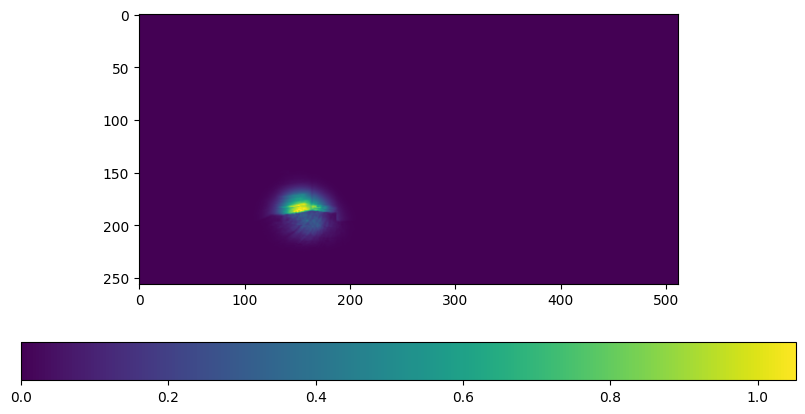

In [20]:
test_width = 512
test_height = 256

vis_ctx: rr.RenderContext = rr.RenderContext(bounces=2, spp=16, bsdf_sampling=True, emitter_sampling=True, mis_beta=4.0)


target_resolution = (512, 256)


# p = mi.Point3f(0, 0, 4)
# d = dr.normalize(mi.Vector3f(0, 0.256, -1))

# ray = mi.Ray3f(p, d)
# si = renderer.scene.ray_intersect(ray)
si = renderer.sample_sensor_first_si()

N = si.n
wi = si.to_world(si.wi)
p = si.p


print(f"Normal : {N}")
print(f"In dir : {wi}")
print(f"pos    : {p}")
# print(f"bsdf   : {si.bsdf()}")

res = renderer.build_distribution_on_surface(si, target_resolution, render_context=vis_ctx, include_brdf=True)

res_np = utils.res_to_numpy_1(res, *target_resolution)
gamma_corrected = utils.gamma_correct(res_np)


fig, ax = plt.subplots(1, 1, figsize=(10, 5))
map = ax.imshow(res_np)
fig.colorbar(map, orientation="horizontal", ax=ax)

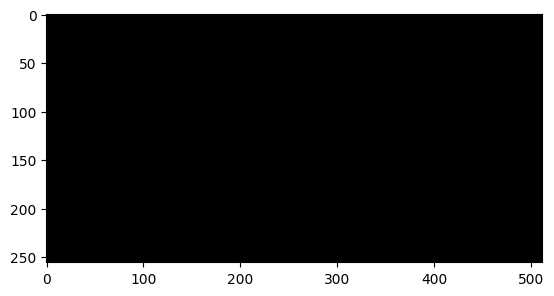

In [27]:
test_width = 512
test_height = 256

vis_ctx: rr.RenderContext = rr.RenderContext(bounces=2, spp=1, bsdf_sampling=True, emitter_sampling=True, mis_beta=4.0)


target_resolution = (512, 256)
res = renderer.build_distribution_floating(mi.Point3f(0, 0, 0), target_resolution, vis_ctx)

res_np = utils.res_to_numpy_3(res, *target_resolution)

# Put tonemapping into different function, add one for gamma correction and apply them using parameters ?
res_np = res_np / (res_np + 1)

fig, ax = plt.subplots()
ax.imshow(res_np)

(512, 256, 3)


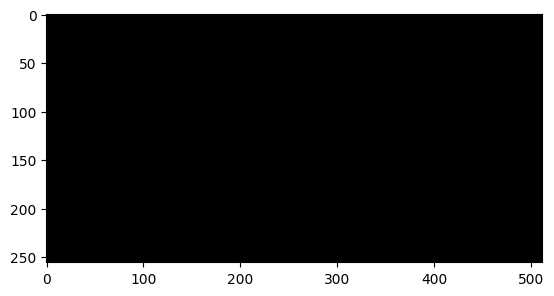

In [28]:
rng = dr.rng(0)

domain = dr.auto.Array2f(dr.two_pi, dr.pi)

num_samples = 5000000
pos = mi.Point3f(0, 0, 0)

samples = rng.random(dr.auto.Array2f, (2, num_samples)) * domain

render_results = renderer.eval_samples(samples, pos).numpy().transpose()

# Define bins
nx, ny = (512, 256)
edges_x = np.linspace(0, 2*np.pi, nx+1)
edges_y = np.linspace(0, np.pi, ny+1)

np_samples = samples.numpy().transpose()

# Digitize samples into bins
ix = np.searchsorted(edges_x, np_samples[:,0], side="right") - 1
iy = np.searchsorted(edges_y, np_samples[:,1], side="right") - 1

# Mask out-of-range samples
mask = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)

ix, iy, values = ix[mask], iy[mask], render_results[mask]

# Create accumulator array
result = np.zeros((nx, ny, 3), dtype=float)
counts = np.zeros((nx, ny), dtype=int)

# Aggregate: sum values per bin
np.add.at(result, (ix, iy), values)
np.add.at(counts, (ix, iy), 1)

print(result.shape)
plt.imshow((result / np.expand_dims(counts, -1)).transpose((1, 0, 2)))